# Paint and filters

Gradients, patterns, clip paths and masks give shapes their paint; filter primitives add shadows, noise,
lighting, distortion, images and color changes.

Run it as ``python 05_paint_and_filters.py`` or open ``05_paint_and_filters.ipynb`` to see each step.

In [1]:
import svgwriter as svg
from svgwriter.model.elements import filters as fe

## Paint

Paint servers are values you pass as `fill` or `stroke`. A gradient takes `Stop`s along its axis;
a `Pattern` repeats a tile of graphics.

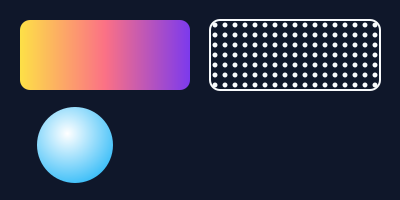

In [2]:
PAINT_W, PAINT_H = 400, 200
paint = svg.Document(PAINT_W, PAINT_H)
paint.rect(0, 0, PAINT_W, PAINT_H, fill="#0f172a")

sunset = svg.LinearGradient(svg.Stop(0, "#fde047"), svg.Stop(0.5, "#fb7185"), svg.Stop(1, "#7c3aed"), x1=0, y1=0, x2=1, y2=0)
orb = paint.radial_gradient(svg.Stop(0, "white"), svg.Stop(1, "#38bdf8"), cx=0.4, cy=0.35, r=0.7)
dots = paint.define(svg.Pattern(svg.circle(5, 5, 2.5, fill="#f8fafc"), width=10, height=10, pattern_units="userSpaceOnUse"))

paint.rect(20, 20, 170, 70, rx=10, fill=sunset)
paint.circle(75, 145, 38, fill=orb)
paint.rect(210, 20, 170, 70, rx=10, fill=dots, stroke="#f8fafc", stroke_width=2)
paint

A `ClipPath` keeps only what lies inside its shapes: a stripe pattern clipped to a star.

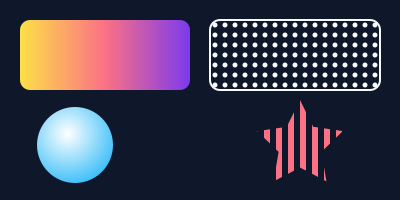

In [3]:
stripes = paint.define(svg.Pattern(svg.rect(0, 0, 6, 12, fill="#fb7185"), width=12, height=12, pattern_units="userSpaceOnUse"))
star_clip = paint.define(svg.ClipPath(svg.builder.star(300, 145, 45, points=5)))
paint.add(svg.Rect(250, 100, 100, 90, fill=stripes, clip_path=star_clip))
paint

A `Mask` uses the luminance of its content as opacity: white keeps, black hides, grey is in between.
A gradient mask fades a circle out toward its right edge.

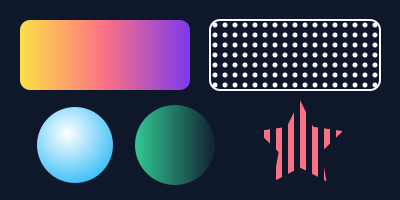

In [4]:
fade = svg.LinearGradient(svg.Stop(0, "white"), svg.Stop(1, "black"), x1=0, y1=0, x2=1, y2=0)
veil = paint.define(svg.Mask(svg.Rect(130, 100, 90, 90, fill=fade), x=130, y=100, width=90, height=90, mask_units="userSpaceOnUse"))
paint.add(svg.Circle(175, 145, 40, fill="#34d399", mask=veil))
paint

## Filters

Filters are defined once with `doc.define(...)` and referenced by shapes through `filter=`.
Primitives chain: turbulence noise, desaturated by a color matrix, makes a paper texture.

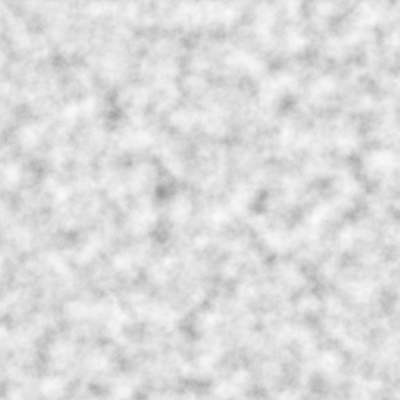

In [5]:
SIZE = 400
TILE = 160

doc = svg.Document(SIZE, SIZE)
noise = fe.FeTurbulence(0.04, 4, seed=7, type=fe.TurbulenceType.FRACTAL_NOISE)
paper = doc.define(svg.Filter(noise, fe.FeColorMatrix.saturate(0), x=0, y=0, width="100%", height="100%"))
doc.add(svg.Rect(0, 0, SIZE, SIZE, filter=paper))
doc

`svg.filters.drop_shadow` is a ready-made filter for a soft shadow; `svg.filters` has more.

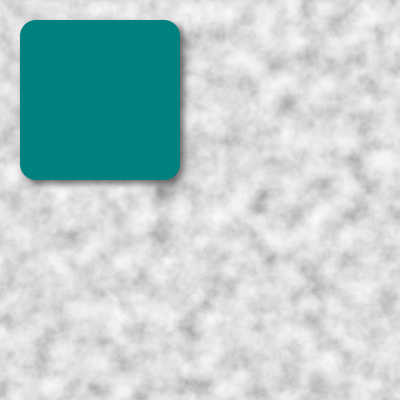

In [6]:
shadow = doc.define(svg.filters.drop_shadow(4, 4, 3, "black", 0.5))
doc.add(svg.Rect(20, 20, TILE, TILE, rx=16, fill="teal", filter=shadow))
doc

Lighting: blur the alpha into a bump map, light it with a point light, clip the highlight to the
shape and add it back onto the source graphic.

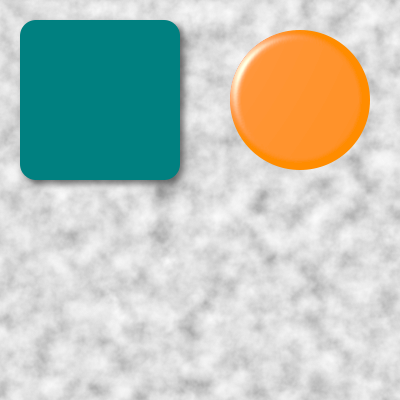

In [7]:
bump = fe.FeGaussianBlur(4, in_=fe.StandardInput.SOURCE_ALPHA)
light = fe.FeSpecularLighting(
    fe.FePointLight(-50, -100, 200),
    in_=bump,
    surface_scale=5,
    specular_constant=0.8,
    specular_exponent=20,
    lighting_color="white",
)
clipped = fe.FeComposite(fe.CompositeOperator.IN, in_=light, in2=fe.StandardInput.SOURCE_ALPHA)
shine = fe.FeComposite(fe.CompositeOperator.ARITHMETIC, in_=fe.StandardInput.SOURCE_GRAPHIC, in2=clipped, k1=0, k2=1, k3=1, k4=0)
embossed = doc.define(svg.Filter(bump, light, clipped, shine))
doc.add(svg.Circle(300, 100, 70, fill="darkorange", filter=embossed))
doc

A color matrix on text: `FeColorMatrix.grayscale()` removes the purple.

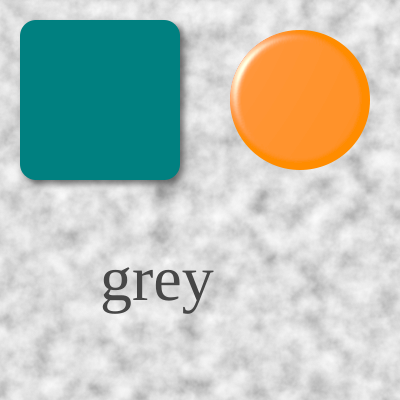

In [8]:
grey = doc.define(svg.Filter(fe.FeColorMatrix.grayscale()))
doc.add(svg.Text("grey", x=100, y=300, font_size=64, fill="purple", filter=grey))
doc

## Light, distortion and images

A spot light shines on a star whose blurred alpha is its height map. Turbulence noise drives a
displacement map that ripples text. `FeImage` pulls a referenced element into the filter, `FeTile`
repeats it, and a composite keeps it inside the circle.

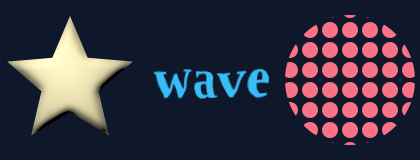

In [9]:
STAGE_W, STAGE_H = 420, 160
stage = svg.Document(STAGE_W, STAGE_H)
stage.rect(0, 0, STAGE_W, STAGE_H, fill="#0f172a")

height = fe.FeGaussianBlur(5, in_=fe.StandardInput.SOURCE_ALPHA)
spot = fe.FeDiffuseLighting(
    fe.FeSpotLight(40, 10, 90, points_at_x=70, points_at_y=80, specular_exponent=4, limiting_cone_angle=40),
    in_=height, surface_scale=6, diffuse_constant=1.3, lighting_color="#fde68a",
)
lit = stage.define(svg.Filter(height, spot, fe.FeComposite(fe.CompositeOperator.IN, in2=fe.StandardInput.SOURCE_ALPHA)))
stage.add(svg.builder.star(70, 82, 66, 30, fill="white", filter=lit))

ripple = fe.FeTurbulence(0.02, 2, seed=5)
warp = stage.define(svg.Filter(ripple, fe.FeDisplacementMap(7, svg.Channel.R, svg.Channel.G,
                                                            in_=fe.StandardInput.SOURCE_GRAPHIC, in2=ripple)))
stage.text("wave", x=210, y=95, font_size=54, font_weight="bold", fill="#38bdf8", text_anchor="middle", filter=warp)

stage.define(svg.circle(10, 10, 8, fill="#fb7185", id="spot"))
swatch = fe.FeImage("#spot", x=0, y=0, width=20, height=20)
wall = stage.define(svg.Filter(swatch, fe.FeTile(in_=swatch), fe.FeComposite(fe.CompositeOperator.IN, in2=fe.StandardInput.SOURCE_ALPHA),
                               x=0, y=0, width="100%", height="100%", filter_units="userSpaceOnUse"))
stage.circle(350, 80, 65, fill="white", filter=wall)
stage

Save all three, the filters with an XML doctype.

In [10]:
paint.save("05_paint.svg")
doc.save("05_filters.svg", doctype=True)
stage.save("05_lighting.svg")